# Projet Big Data : traitement distribué et modélisation (PySpark)

Ce notebook prend la suite de `projet.ipynb` (collecte). Il lit les fichiers bruts de `data/raw/`, les nettoie avec **PySpark**, extrait les mots les plus fréquents des descriptions avec une procédure **MapReduce**, puis entraîne **trois modèles PySpark ML** pour prédire le salaire annuel d'une offre.

> Environnement d'exécution : Python 3.13, PySpark 4.0.1, Java 21, Spark en mode local (`local[*]`). Sous Windows, Spark nécessite en plus Java 17+ et `winutils.exe` (variable `HADOOP_HOME`) pour écrire les fichiers Parquet.

## Étape 1 : Architecture et flux de données

```
 ┌────────────────────┐   ┌─────────────────────────┐
 │ API France Travail │   │ Welcome to the Jungle   │
 │ (requests, OAuth2) │   │ (Selenium + BeautifulSoup)│
 └─────────┬──────────┘   └────────────┬────────────┘
           │  INGESTION (projet.ipynb)  │
           ▼                            ▼
 ┌──────────────────────────────────────────────────┐
 │ STOCKAGE BRUT  data/raw/                          │
 │  france_travail_AAAAMMJJ.json (réponse API brute) │
 │  offres_france_travail.csv, offres_wttj.csv       │
 └─────────────────────────┬────────────────────────┘
                           ▼
 ┌──────────────────────────────────────────────────┐
 │ SPARK PROCESSING (ce notebook)                    │
 │  union des sources → doublons → valeurs manquantes│
 │  → salaire annuel → compétences → MapReduce top-k │
 └─────────────────────────┬────────────────────────┘
                           ▼
 ┌──────────────────────────────────────────────────┐
 │ ZONE NETTOYÉE  data/processed/offres_clean.parquet│
 │  (partitionnée par source)                        │
 └─────────────────────────┬────────────────────────┘
                           ▼
 ┌──────────────────────────────────────────────────┐
 │ MODELING (PySpark ML) : régression linéaire,      │
 │ Random Forest, Gradient Boosted Trees → salaire   │
 └──────────────────────────────────────────────────┘
```

**Choix des formats.**
- *JSON brut* pour la réponse de l'API : c'est le format natif, on le garde sans transformation pour pouvoir rejouer le traitement.
- *CSV* pour la version aplatie de chaque source : lisible, simple à produire depuis pandas, et lu directement par Spark.
- *Parquet* pour les données nettoyées : format colonnaire et compressé, le schéma est stocké avec les données (pas de ré-inférence des types), et Spark ne lit que les colonnes utiles à chaque requête.

**Partitionnement.** Les données nettoyées sont partitionnées par `source` (`partitionBy("source")`) : chaque source a un format et une qualité différents, et ce découpage permet de relire ou de recalculer une source sans toucher à l'autre. Avec ~2 000 offres, un partitionnement plus fin (par date ou par département) créerait surtout de très petits fichiers, ce qui dégrade les performances de Spark.

In [1]:
import os, re
from operator import add

import matplotlib.pyplot as plt
import pandas as pd

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, Imputer, StopWordsRemover
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

spark = (SparkSession.builder
         .appName("BigData2026-MarcheEmploi")
         .master("local[*]")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

RAW_DIR = "data/raw"
PROCESSED_DIR = "data/processed"
SEED = 42

ModuleNotFoundError: No module named 'pyspark'

## Étape 4 : Traitement distribué avec Spark

### 4.1 Chargement des données brutes
Les deux sources ont été aplaties avec le même schéma dans `projet.ipynb`, on les réunit avec `unionByName`. Les descriptions contiennent des retours à la ligne et des guillemets, d'où les options `multiLine` et `escape`.

In [ ]:
def lire_csv(nom):
    return (spark.read
            .option("header", True)
            .option("multiLine", True)
            .option("escape", '"')
            .option("encoding", "UTF-8")
            .csv(os.path.join(RAW_DIR, nom)))

df_ft = lire_csv("offres_france_travail.csv")
df_wttj = lire_csv("offres_wttj.csv")
# le BOM utf-8-sig peut se retrouver dans le nom de la première colonne
df_ft = df_ft.toDF(*[c.replace("﻿", "") for c in df_ft.columns])
df_wttj = df_wttj.toDF(*[c.replace("﻿", "") for c in df_wttj.columns])

df_raw = df_ft.unionByName(df_wttj, allowMissingColumns=True)
print(f"France Travail : {df_ft.count()} offres | WTTJ : {df_wttj.count()} offres | total : {df_raw.count()}")
df_raw.groupBy("source").count().show()
df_raw.printSchema()

France Travail : 1037 offres | WTTJ : 1013 offres | total : 2050


+------------------+-----+
|            source|count|
+------------------+-----+
|    France travail| 1037|
|welcometothejungle| 1013|
+------------------+-----+

root
 |-- id: string (nullable = true)
 |-- intitule: string (nullable = true)
 |-- description: string (nullable = true)
 |-- type_contrat: string (nullable = true)
 |-- nb_heure_travail: string (nullable = true)
 |-- experience: string (nullable = true)
 |-- experience_exige: string (nullable = true)
 |-- salaire_libelle: string (nullable = true)
 |-- salaire_min: string (nullable = true)
 |-- salaire_max: string (nullable = true)
 |-- ville: string (nullable = true)
 |-- code_postal: string (nullable = true)
 |-- commune: string (nullable = true)
 |-- entreprise: string (nullable = true)
 |-- secteur_activite: string (nullable = true)
 |-- competences: string (nullable = true)
 |-- formation_requise: string (nullable = true)
 |-- langues: string (nullable = true)
 |-- type_de_poste: string (nullable = true)
 |-- source: st

In [ ]:
def taux_manquants(df):
    total = df.count()
    exprs = [(F.sum(F.when(F.col(c).isNull() | (F.trim(F.col(c)) == ""), 1).otherwise(0)) / total * 100).alias(c)
             for c in df.columns]
    return df.select(exprs).toPandas().T.rename(columns={0: "% manquant"}).round(1)

taux_manquants(df_raw).sort_values("% manquant", ascending=False)

,% manquant
langues,97.1
nb_heure_travail,88.4
salaire_min,86.1
salaire_max,86.1
salaire_libelle,79.8
formation_requise,79.1
experience_exige,49.4
experience,49.4
competences,44.0
secteur_activite,30.8


### 4.2 Nettoyage : doublons et valeurs manquantes

1. **Doublons exacts** : même `id` dans une source (une offre remontée par plusieurs mots-clés).
2. **Doublons inter-sources** : une même offre publiée sur France Travail et sur WTTJ a des identifiants différents, on la repère par sa description normalisée (minuscules, sans ponctuation ni espaces).
3. **Intitulés WTTJ erronés** : sur WTTJ le titre est découpé en plusieurs balises HTML et le scraper n'en a souvent récupéré qu'un morceau (« Data », « Business », voire un badge comme « Recrute activement ! »). On reconstruit donc l'intitulé à partir de l'URL de l'offre, qui contient le titre complet. Pour la même raison, la colonne `entreprise` de WTTJ n'est pas fiable et n'est pas utilisée.
4. **Valeurs manquantes** : les colonnes catégorielles reçoivent la modalité « Non renseigné » (l'absence d'information est elle-même informative) ; l'expérience numérique manquante sera imputée par la médiane dans le pipeline ML ; les offres sans description ni intitulé sont supprimées.

In [ ]:
n0 = df_raw.count()
df = df_raw.dropDuplicates(["source", "id"])
n1 = df.count()

df = (df
      .withColumn("desc_norm", F.regexp_replace(F.lower(F.coalesce("description", F.lit(""))), r"[^a-z0-9àâçéèêëîïôûùüÿœ]", ""))
      .withColumn("desc_norm", F.when(F.length("desc_norm") > 50, F.col("desc_norm"))))
# on ne déduplique que les offres ayant une vraie description, en gardant la version France Travail (plus complète)
avec_desc = df.filter(F.col("desc_norm").isNotNull())
sans_desc = df.filter(F.col("desc_norm").isNull())
from pyspark.sql.window import Window
w = Window.partitionBy("desc_norm").orderBy(F.col("source").asc())
avec_desc = avec_desc.withColumn("_rang", F.row_number().over(w)).filter("_rang = 1").drop("_rang")
df = avec_desc.unionByName(sans_desc).drop("desc_norm")
n2 = df.count()

# Côté WTTJ, le titre affiché était découpé en plusieurs balises : la colonne intitule ne contient souvent
# qu'un fragment ("Data", "Business"...). L'URL de l'offre contient en revanche le titre complet :
# "data-analyst-h-f_paris-la-defense_GS_pKVRy2N" -> "Data Analyst"
titre_depuis_url = F.initcap(F.trim(F.regexp_replace(
    F.regexp_replace(F.regexp_extract("id", r"^([^_]+)", 1), r"(^|-)(h-f|f-h|hf|fh|m-f|f-m)(-|$)", "$3"), "-", " ")))
df = df.withColumn("intitule_brut", F.col("intitule"))
df = df.withColumn("intitule", F.when(F.col("source") == "welcometothejungle", titre_depuis_url).otherwise(F.col("intitule")))
df.filter(F.col("source") == "welcometothejungle").select("id", "intitule_brut", "intitule").show(5, truncate=50)
df = df.drop("intitule_brut")

df = df.filter(F.col("intitule").isNotNull() & F.col("description").isNotNull())
n3 = df.count()
print(f"Brut : {n0} | après doublons id : {n1} | après doublons inter-sources : {n2} | après suppression des offres vides : {n3}")

+-------------------------------------------------+--------------+-------------------------------------------+
|                                               id| intitule_brut|                                   intitule|
+-------------------------------------------------+--------------+-------------------------------------------+
|           analytics-engineer_paris_MIRAK_zxY1AV3|        Analyt|                         Analytics Engineer|
|                      senior-product-data-analyst|Senior Product|                Senior Product Data Analyst|
|                    data-lead_paris_MAKIP_aVJGrYP|          Data|                                  Data Lead|
|                  senior-analytics-engineer_paris|        Senior|                  Senior Analytics Engineer|
|analyst-strategic-sales-shark-clean-home-fr_paris|       Analyst|Analyst Strategic Sales Shark Clean Home Fr|
+-------------------------------------------------+--------------+-------------------------------------------+
o

Brut : 2050 | après doublons id : 2050 | après doublons inter-sources : 1987 | après suppression des offres vides : 1975


### 4.3 Normalisation du salaire (variable cible)

Les libellés n'ont pas le même format selon la source :
- France Travail : « Annuel de 40000.0 Euros à 47000.0 Euros sur 12 mois », « Mensuel de 1407.0 Euros à 1638.0 Euros », « Horaire de 11.88 Euros » ;
- WTTJ : « EUR 50000 - 55000 / an », mais aussi « EUR 1200 - 1400 / an » qui est en réalité un salaire **mensuel** (gratification de stage), ou « < 1,3K € par mois ».

On extrait les montants, on prend le milieu de la fourchette et on ramène tout à un **salaire annuel brut** : ×12 pour un mensuel, ×1 607 h (durée légale annuelle) pour un horaire, un montant inférieur à 5 000 € annoncé « / an » est considéré comme mensuel et, à l'inverse, un « mensuel » supérieur à 10 000 € est en réalité annuel. Les valeurs hors de [6 000 ; 200 000] € sont jugées aberrantes et mises à null.

In [ ]:
@F.udf(T.DoubleType())
def salaire_annuel(libelle):
    if libelle is None:
        return None
    lib = libelle.lower().replace("\xa0", " ")
    lib = re.sub(r"sur\s+[\d.,]+\s+mois", "", lib)
    montants = []
    for nombre, k in re.findall(r"(\d+(?:[.,]\d+)?)\s*(k?)", lib):
        valeur = float(nombre.replace(",", "."))
        montants.append(valeur * 1000 if k else valeur)
    montants = [m for m in montants if m > 0]
    if not montants:
        return None
    moyenne = sum(montants[:2]) / len(montants[:2])
    if "horaire" in lib or "heure" in lib:
        annuel = moyenne * 1607
    elif ("mensuel" in lib or "mois" in lib) and moyenne > 10000:
        annuel = moyenne        # montant annuel saisi par erreur comme mensuel (ex. « Mensuel de 26000 Euros »)
    elif "mensuel" in lib or "mois" in lib or moyenne < 5000:
        annuel = moyenne * 12
    else:
        annuel = moyenne
    return float(annuel) if 6000 <= annuel <= 200000 else None

df = df.withColumn("salaire_annuel", salaire_annuel("salaire_libelle"))
df.select("source", "salaire_libelle", "salaire_annuel").filter(F.col("salaire_libelle").isNotNull()).show(10, truncate=60)
df.groupBy("source").agg(F.count("*").alias("offres"),
                         F.count("salaire_annuel").alias("avec_salaire"),
                         F.round(F.expr("percentile_approx(salaire_annuel, 0.5)"), 0).alias("salaire_median")).show()

+------------------+------------------------------------------------------------+--------------+
|            source|                                             salaire_libelle|salaire_annuel|
+------------------+------------------------------------------------------------+--------------+
|    France travail|                     Annuel de 50000.0 Euros à 55000.0 Euros|       52500.0|
|    France travail|                     Annuel de 45000.0 Euros à 50000.0 Euros|       47500.0|
|    France travail|                     Annuel de 38000.0 Euros à 42000.0 Euros|       40000.0|
|    France travail|                     Annuel de 40000.0 Euros à 45000.0 Euros|       42500.0|
|    France travail|                     Annuel de 25000.0 Euros à 35000.0 Euros|       30000.0|
|    France travail|                                     Annuel de 26000.0 Euros|       26000.0|
|    France travail|                     Annuel de 70000.0 Euros à 80000.0 Euros|       75000.0|
|    France travail|Annuel de 

+------------------+------+------------+--------------+
|            source|offres|avec_salaire|salaire_median|
+------------------+------+------------+--------------+
|    France travail|  1008|         271|       47500.0|
|welcometothejungle|   967|         122|       45000.0|
+------------------+------+------------+--------------+



### 4.4 Variables explicatives

- `categorie_poste` : déduite de l'intitulé (Data Engineer, Data Scientist, Data Analyst, ML / IA, BI…), plus fiable que le mot-clé de recherche.
- `niveau_poste` : séniorité lue dans l'intitulé (Junior, Senior / Confirmé, Lead / Manager).
- `contrat`, `niveau_formation` (harmonisé : Bac+2, Bac+3, Bac+5 et plus), `region` (Île-de-France / autres régions / étranger, depuis le code postal).
- `annees_experience` : depuis le champ expérience de France Travail (« 3 An(s) », « 6 Mois », « Débutant accepté ») ou, à défaut, depuis la description (« 3 ans d'expérience »).
- `skill_*` : présence de 22 compétences techniques dans la description et les compétences listées.

In [ ]:
texte = F.lower(F.concat_ws(" ", "intitule", "description", "competences"))
titre = F.lower(F.col("intitule"))

df = df.withColumn("categorie_poste",
    F.when(titre.rlike(r"stagi|stage|alternan|apprenti"), "Stage / Alternance")
     .when(titre.rlike(r"machine learning|ml |mlops|\bia\b|\bai\b|intelligence artificielle|deep learning"), "ML / IA")
     .when(titre.rlike(r"scien"), "Data Scientist")
     .when(titre.rlike(r"engineer|ingénieur|ingenieur|architect|devops|développeur|developpeur"), "Data Engineer")
     .when(titre.rlike(r"\bbi\b|business intelligence|power bi|décisionnel|decisionnel"), "BI")
     .when(titre.rlike(r"analy"), "Data Analyst")
     .when(titre.rlike(r"manager|chef|lead|head|directeur|responsable"), "Management")
     .otherwise("Autre"))

df = df.withColumn("contrat",
    F.when(F.col("type_contrat").rlike(r"(?i)cdi"), "CDI")
     .when(F.col("type_contrat").rlike(r"(?i)cdd|temporaire|intérim|mission"), "CDD / Intérim")
     .when(F.col("type_contrat").rlike(r"(?i)stage|alternance|apprentissage"), "Stage / Alternance")
     .when(F.col("type_contrat").rlike(r"(?i)freelance|indépendant|libéral"), "Freelance")
     .when(F.col("type_contrat").isNull(), "Non renseigné")
     .otherwise("Autre"))

formation = F.lower(F.coalesce("formation_requise", F.lit("")))
df = df.withColumn("niveau_formation",
    F.when(formation.rlike(r"bac\+5|master|postgraduate|doctor|ingénieur"), "Bac+5 et plus")
     .when(formation.rlike(r"bac\+3|bac\+4|licence|bachelor"), "Bac+3/4")
     .when(formation.rlike(r"bac\+2|bts|dut|associate|bac ou"), "Bac+2 et moins")
     .otherwise("Non renseigné"))

cp = F.lpad(F.regexp_extract(F.coalesce("code_postal", F.lit("")), r"^(\d+)", 1), 5, "0")
dep = F.substring(cp, 1, 2)
df = df.withColumn("region",
    F.when(F.col("code_postal").isNull(), "Non renseigné")
     .when(dep.isin("75", "77", "78", "91", "92", "93", "94", "95") & (F.length(F.regexp_extract("code_postal", r"^(\d+)", 1)) >= 4), "Île-de-France")
     .when(F.col("source") == "welcometothejungle",
           F.when(F.col("commune").rlike(r"(?i)barcelona|london|berlin|madrid|lisboa|bruxelles|genève|luxembourg|amsterdam|milano|new york"), "Étranger")
            .otherwise("Autres régions"))
     .otherwise("Autres régions"))

df = df.withColumn("niveau_poste",
    F.when(titre.rlike(r"senior|sénior|confirm|expérimenté|experimente|expert|\bsr\b"), "Senior / Confirmé")
     .when(titre.rlike(r"lead|principal|head|manager|directeur|directrice|chef|responsable"), "Lead / Manager")
     .when(titre.rlike(r"junior|débutant|debutant|\bjr\b|graduate"), "Junior")
     .otherwise("Non précisé"))

exp_txt = F.lower(F.coalesce("experience", F.lit("")))
nb_ans = F.regexp_extract(exp_txt, r"(\d+)\s*an", 1)
nb_mois = F.regexp_extract(exp_txt, r"(\d+)\s*mois", 1)
desc_ans = F.regexp_extract(F.lower("description"), r"(\d{1,2})\s*(?:\+\s*)?(?:ans|années|years)\s+(?:d.|of\s+)?(?:expérience|experience)", 1)
df = df.withColumn("annees_experience",
    F.when(nb_ans != "", nb_ans.cast("double"))
     .when(nb_mois != "", F.round(nb_mois.cast("double") / 12, 1))
     .when(exp_txt.rlike(r"débutant"), F.lit(0.0))
     .when(desc_ans != "", desc_ans.cast("double"))
     .otherwise(F.lit(None).cast("double")))
df = df.withColumn("annees_experience", F.when(F.col("annees_experience") <= 20, F.col("annees_experience")))

SKILLS = {
    "python": r"\bpython\b", "sql": r"\bsql\b|mysql|postgres", "r": r"\blangage r\b|\br\b,|\br/|, r\b|\brstudio\b",
    "spark": r"\bspark\b|pyspark", "hadoop": r"hadoop|hdfs|hive", "aws": r"\baws\b|amazon web services",
    "azure": r"azure", "gcp": r"\bgcp\b|google cloud|bigquery", "power_bi": r"power ?bi", "tableau": r"\btableau\b",
    "excel": r"\bexcel\b|vba", "machine_learning": r"machine learning|apprentissage automatique",
    "deep_learning": r"deep learning|tensorflow|pytorch|keras", "nlp_llm": r"\bnlp\b|\bllm|genai|ia générative|generative ai",
    "docker_k8s": r"docker|kubernetes", "airflow": r"airflow", "dbt": r"\bdbt\b", "snowflake": r"snowflake",
    "databricks": r"databricks", "sas": r"\bsas\b", "git": r"\bgit\b|github|gitlab", "statistiques": r"statisti",
}
for nom, motif in SKILLS.items():
    df = df.withColumn(f"skill_{nom}", texte.rlike(motif).cast("int"))
SKILL_COLS = [f"skill_{s}" for s in SKILLS]
df = df.withColumn("nb_skills", sum(F.col(c) for c in SKILL_COLS))

df.select("intitule", "categorie_poste", "niveau_poste", "contrat", "niveau_formation", "region", "annees_experience", "nb_skills", "salaire_annuel").show(10, truncate=40)

+----------------------------------------+------------------+--------------+-------------+----------------+--------------+-----------------+---------+--------------+
|                                intitule|   categorie_poste|  niveau_poste|      contrat|niveau_formation|        region|annees_experience|nb_skills|salaire_annuel|
+----------------------------------------+------------------+--------------+-------------+----------------+--------------+-----------------+---------+--------------+
|               Ingénieur IA Vision (H/F)|           ML / IA|   Non précisé|CDD / Intérim|   Non renseigné|Autres régions|              0.0|        3|          NULL|
|Responsable Transformation Digitale &...|        Management|Lead / Manager|          CDI|   Non renseigné|Autres régions|              3.0|        5|       52500.0|
|                       Data Engineer H/F|     Data Engineer|   Non précisé|          CDI|   Non renseigné|Autres régions|              3.0|        9|          NULL|
|   

**Filtrage du périmètre.** Les recherches par mots-clés de France Travail remontent aussi des offres hors sujet (agent de conditionnement, électricien…). On garde les offres dont l'intitulé relève de la data, ou dont la description cite au moins 3 des compétences techniques ci-dessus.

In [ ]:
MOTIF_DATA = (r"data|donn[ée]e|analy|\bbi\b|business intelligence|machine learning|\bia\b|\bai\b|intelligence artificielle"
              r"|statisti|scien|quant|décisionnel|decisionnel|dataviz|mlops|llm|nlp")
avant = df.groupBy("source").count().withColumnRenamed("count", "avant")
df = df.filter(F.lower("intitule").rlike(MOTIF_DATA) | (F.col("nb_skills") >= 3))
avant.join(df.groupBy("source").count().withColumnRenamed("count", "après"), "source").show()

+------------------+-----+-----+
|            source|avant|après|
+------------------+-----+-----+
|    France travail| 1008|  918|
|welcometothejungle|  967|  940|
+------------------+-----+-----+



In [ ]:
# valeurs manquantes après nettoyage, sur les variables utilisées par la suite
COLS_ANALYSE = ["categorie_poste", "niveau_poste", "contrat", "niveau_formation", "region", "annees_experience", "nb_skills", "salaire_annuel"]
taux_manquants(df.select(COLS_ANALYSE))

,% manquant
categorie_poste,0.0
niveau_poste,0.0
contrat,0.0
niveau_formation,0.0
region,0.0
annees_experience,48.9
nb_skills,0.0
salaire_annuel,80.4


### 4.5 Sauvegarde au format Parquet, partitionné par source

In [ ]:
df = df.cache()
(df.drop("competences", "langues")
   .write.mode("overwrite")
   .partitionBy("source")
   .parquet(os.path.join(PROCESSED_DIR, "offres_clean.parquet")))

df_clean = spark.read.parquet(os.path.join(PROCESSED_DIR, "offres_clean.parquet"))
print(f"{df_clean.count()} offres nettoyées relues depuis Parquet")
print(sorted(os.listdir(os.path.join(PROCESSED_DIR, "offres_clean.parquet"))))

1858 offres nettoyées relues depuis Parquet
['._SUCCESS.crc', '_SUCCESS', 'source=France travail', 'source=welcometothejungle']


### 4.6 Analyse NLP : top-k mots des descriptions (MapReduce)

Implémentation explicite du schéma MapReduce avec l'API RDD de Spark :
- **Map** (`flatMap`) : chaque description est découpée en mots (minuscules, sans ponctuation), puis chaque mot utile est émis sous la forme d'une paire `(mot, 1)` ;
- **Shuffle** : Spark regroupe les paires de même clé sur la même partition ;
- **Reduce** (`reduceByKey`) : les compteurs de chaque mot sont additionnés ;
- **Top-k** : `takeOrdered(k)` récupère les k mots les plus fréquents sans trier tout le RDD.

Les mots vides français et anglais (listes fournies par `StopWordsRemover` de Spark ML) et le vocabulaire générique des annonces sont filtrés.

In [ ]:
K = 30
STOPWORDS = set(StopWordsRemover.loadDefaultStopWords("french")) | set(StopWordsRemover.loadDefaultStopWords("english"))
STOPWORDS |= {"h/f", "f/h", "hf", "fh", "h", "f", "être", "plus", "afin", "ainsi", "tant", "sein", "chez", "dont", "tous",
              "toutes", "tout", "toute", "nos", "notre", "vos", "votre", "leurs", "leur", "aussi", "très", "bien", "faire",
              "etc", "via", "car", "comme", "entre", "selon", "lors", "sous", "sans", "avoir", "peut", "êtes", "serez",
              "poste", "mission", "missions", "profil", "recherché", "descriptif", "vous", "nous", "ans", "an", "mois", "jours",
              "will", "within", "also", "new", "work", "voir", "mise", "place"}

def tokeniser(texte):
    mots = re.findall(r"[a-zàâçéèêëîïôûùüÿœ][a-zàâçéèêëîïôûùüÿœ+#.\-]*[a-zàâçéèêëîïôûùüÿœ+#]|[a-z]", (texte or "").lower())
    return [m for m in mots if len(m) > 2 and m not in STOPWORDS]

rdd_desc = df_clean.select("description").rdd.map(lambda row: row["description"])

paires = rdd_desc.flatMap(tokeniser).map(lambda mot: (mot, 1))     # MAP
comptes = paires.reduceByKey(add)                                  # SHUFFLE + REDUCE
top_k = comptes.takeOrdered(K, key=lambda kv: -kv[1])              # TOP-K

print(f"{paires.count()} mots émis, {comptes.count()} mots distincts")
pd.DataFrame(top_k, columns=["mot", "occurrences"])

423047 mots émis, 21159 mots distincts


,mot,occurrences
0,data,9837
1,données,6398
2,équipe,2262
3,équipes,2207
4,expérience,2093
5,solutions,2083
6,clients,1808
7,projets,1807
8,développement,1726
9,outils,1725


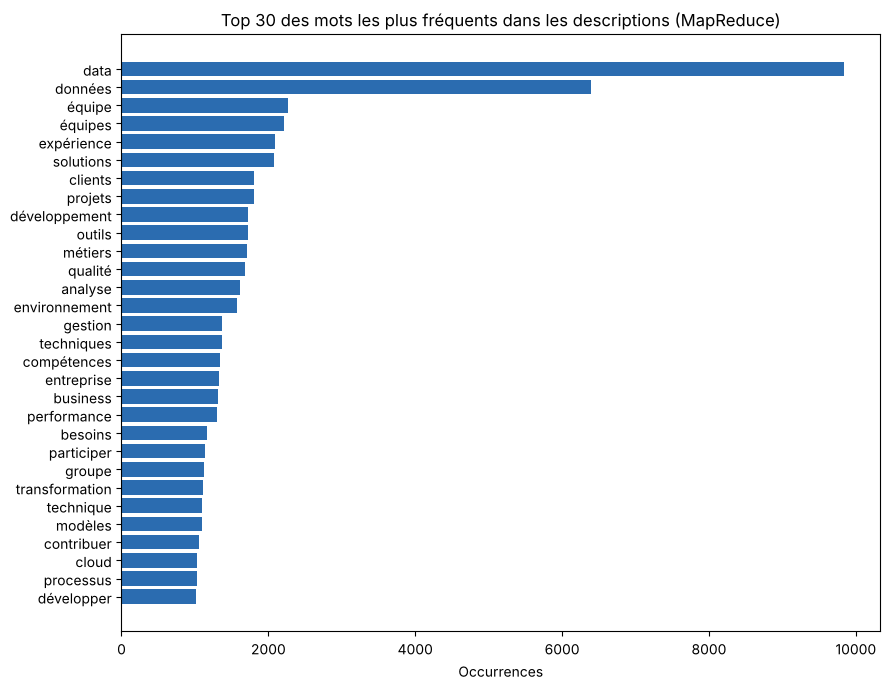

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
mots, n = zip(*top_k[::-1])
ax.barh(mots, n, color="#2b6cb0")
ax.set_title(f"Top {K} des mots les plus fréquents dans les descriptions (MapReduce)")
ax.set_xlabel("Occurrences")
plt.tight_layout()
plt.show()

Même procédure MapReduce, mais avec une clé composite `(source, mot)` pour comparer le vocabulaire des deux sources :

In [ ]:
top_par_source = (df_clean.select("source", "description").rdd
                  .flatMap(lambda r: [((r["source"], m), 1) for m in tokeniser(r["description"])])
                  .reduceByKey(add)
                  .map(lambda kv: (kv[0][0], (kv[0][1], kv[1])))
                  .groupByKey()
                  .mapValues(lambda v: sorted(v, key=lambda x: -x[1])[:15])
                  .collect())
pd.DataFrame({src: [f"{m} ({c})" for m, c in mots] for src, mots in top_par_source})

,welcometothejungle,France travail
0,data (4696),data (5141)
1,données (2485),données (3913)
2,équipe (1219),expérience (1540)
3,équipes (1009),équipes (1198)
4,clients (942),solutions (1141)
5,solutions (942),équipe (1043)
6,business (857),qualité (1022)
7,analyse (847),développement (1010)
8,projets (846),métiers (1006)
9,outils (810),environnement (992)


### 4.7 Analyse des compétences et des salaires

In [ ]:
total = df_clean.count()
freq_skills = (df_clean.select([F.sum(c).alias(c.replace("skill_", "")) for c in SKILL_COLS])
               .toPandas().T.rename(columns={0: "offres"}).sort_values("offres", ascending=False))
freq_skills["% des offres"] = (freq_skills["offres"] / total * 100).round(1)

# salaire médian des offres qui demandent / ne demandent pas chaque compétence
avec_sal = df_clean.filter(F.col("salaire_annuel").isNotNull())
ecarts = []
for c in SKILL_COLS:
    r = avec_sal.groupBy(c).agg(F.expr("percentile_approx(salaire_annuel, 0.5)").alias("med")).collect()
    med = {row[c]: row["med"] for row in r}
    ecarts.append((c.replace("skill_", ""), med.get(1), med.get(0)))
ecarts = pd.DataFrame(ecarts, columns=["compétence", "médiane avec", "médiane sans"]).set_index("compétence")
freq_skills.join(ecarts)

,offres,% des offres,médiane avec,médiane sans
sql,705,37.9,49500.0,46000.0
python,640,34.4,50000.0,45000.0
power_bi,449,24.2,47000.0,48500.0
r,417,22.4,47500.0,47500.0
machine_learning,372,20.0,50000.0,47500.0
nlp_llm,269,14.5,52500.0,47500.0
statistiques,268,14.4,43500.0,50000.0
gcp,243,13.1,52500.0,47500.0
git,240,12.9,50000.0,47500.0
excel,232,12.5,40000.0,50000.0


+------------------+------+--------------+-------------+
|   categorie_poste|offres|salaire_median|salaire_moyen|
+------------------+------+--------------+-------------+
|           ML / IA|    42|       54000.0|      56957.0|
|     Data Engineer|    94|       51500.0|      51500.0|
|        Management|    51|       50000.0|      51458.0|
|                BI|    15|       50000.0|      48468.0|
|    Data Scientist|    20|       47500.0|      47140.0|
|             Autre|    35|       45000.0|      44207.0|
|      Data Analyst|    86|       43000.0|      44335.0|
|Stage / Alternance|    21|       16800.0|      16686.0|
+------------------+------+--------------+-------------+



/tmp/ipykernel_5526/2170248359.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot([pdf_sal.loc[pdf_sal.categorie_poste == c, "salaire_annuel"] for c in ordre], tick_labels=ordre, vert=False)


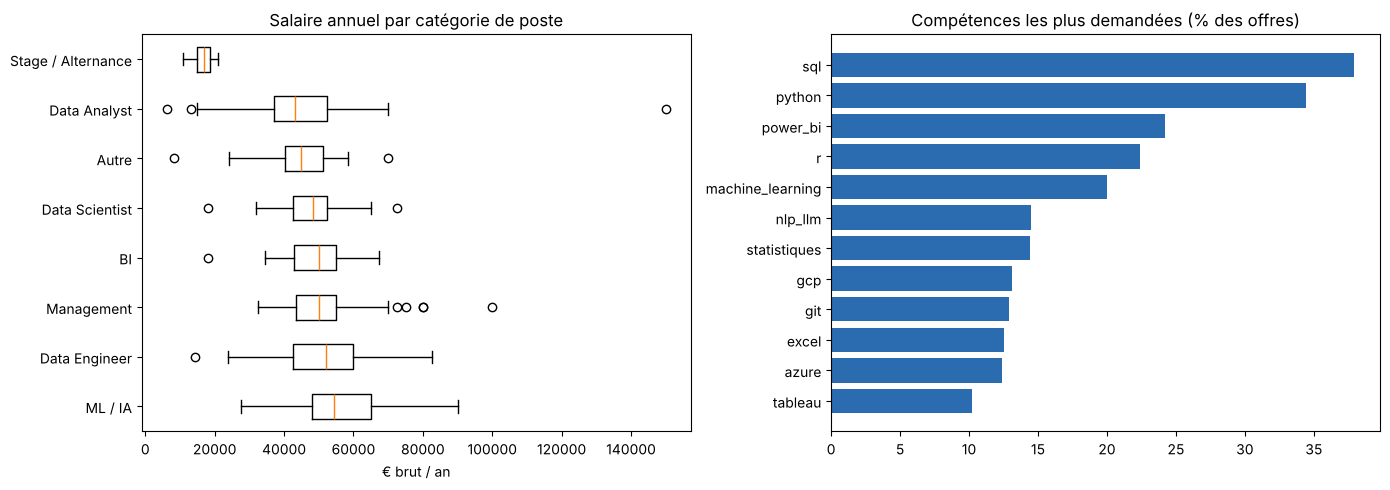

In [ ]:
sal_cat = (avec_sal.groupBy("categorie_poste")
           .agg(F.count("*").alias("offres"),
                F.round(F.expr("percentile_approx(salaire_annuel, 0.5)"), 0).alias("salaire_median"),
                F.round(F.avg("salaire_annuel"), 0).alias("salaire_moyen"))
           .orderBy(F.desc("salaire_median")))
sal_cat.show()

pdf_sal = avec_sal.select("categorie_poste", "salaire_annuel").toPandas()
ordre = sal_cat.toPandas()["categorie_poste"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot([pdf_sal.loc[pdf_sal.categorie_poste == c, "salaire_annuel"] for c in ordre], tick_labels=ordre, vert=False)
axes[0].set_title("Salaire annuel par catégorie de poste")
axes[0].set_xlabel("€ brut / an")
top_sk = freq_skills.head(12)[::-1]
axes[1].barh(top_sk.index, top_sk["% des offres"], color="#2b6cb0")
axes[1].set_title("Compétences les plus demandées (% des offres)")
plt.tight_layout()
plt.show()

## Étape 5 : Modélisation prédictive du salaire (PySpark ML)

**Cible** : `salaire_annuel` (€ brut / an), disponible seulement pour les offres qui affichent un salaire.
**Variables** : catégorie de poste, séniorité, contrat, niveau de formation, région, source, années d'expérience (imputées par la médiane), nombre de compétences et 22 indicateurs de compétences.

Les variables catégorielles passent par `StringIndexer` puis `OneHotEncoder` ; le tout est assemblé dans un `VectorAssembler`. Le même pipeline de préparation est partagé par les trois modèles :
1. **Régression linéaire** (avec régularisation ElasticNet) : modèle de référence, interprétable par ses coefficients ;
2. **Random Forest** : capte les non-linéarités et les interactions, robuste au bruit ;
3. **Gradient Boosted Trees** : boosting d'arbres, l'équivalent Spark ML de XGBoost.

Les hyperparamètres de chaque modèle sont choisis par **validation croisée à 3 plis** sur l'échantillon d'apprentissage (80 %) ; l'évaluation finale se fait sur les 20 % restants. Le jeu de test étant petit (~70 offres), on affiche aussi la RMSE moyenne de validation croisée, plus stable.

In [ ]:
CAT_COLS = ["categorie_poste", "niveau_poste", "contrat", "niveau_formation", "region", "source"]
NUM_COLS = ["annees_experience_imp", "nb_skills"] + SKILL_COLS

data = df_clean.filter(F.col("salaire_annuel").isNotNull()).select(CAT_COLS + ["annees_experience", "nb_skills"] + SKILL_COLS + ["salaire_annuel"])
train, test = data.randomSplit([0.8, 0.2], seed=SEED)
train, test = train.cache(), test.cache()
print(f"Offres avec salaire : {data.count()} | apprentissage : {train.count()} | test : {test.count()}")

preparation = [
    Imputer(inputCols=["annees_experience"], outputCols=["annees_experience_imp"], strategy="median"),
    StringIndexer(inputCols=CAT_COLS, outputCols=[c + "_idx" for c in CAT_COLS], handleInvalid="keep"),
    OneHotEncoder(inputCols=[c + "_idx" for c in CAT_COLS], outputCols=[c + "_ohe" for c in CAT_COLS], handleInvalid="keep"),
    VectorAssembler(inputCols=[c + "_ohe" for c in CAT_COLS] + NUM_COLS, outputCol="features"),
]

Offres avec salaire : 364 | apprentissage : 295 | test : 69


In [ ]:
evaluateurs = {m: RegressionEvaluator(labelCol="salaire_annuel", predictionCol="prediction", metricName=m) for m in ["rmse", "mae", "r2"]}

lr = LinearRegression(featuresCol="features", labelCol="salaire_annuel")
rf = RandomForestRegressor(featuresCol="features", labelCol="salaire_annuel", seed=SEED)
gbt = GBTRegressor(featuresCol="features", labelCol="salaire_annuel", seed=SEED)

modeles = {
    "Régression linéaire": (lr, ParamGridBuilder()
                            .addGrid(lr.regParam, [0.01, 0.1, 1.0])
                            .addGrid(lr.elasticNetParam, [0.0, 0.5, 1.0]).build()),
    "Random Forest": (rf, ParamGridBuilder()
                      .addGrid(rf.numTrees, [100, 200])
                      .addGrid(rf.maxDepth, [5, 8, 12]).build()),
    "Gradient Boosted Trees": (gbt, ParamGridBuilder()
                               .addGrid(gbt.maxDepth, [3, 5])
                               .addGrid(gbt.maxIter, [50, 100])
                               .addGrid(gbt.stepSize, [0.05, 0.1]).build()),
}

resultats, pipelines = [], {}
for nom, (estimateur, grille) in modeles.items():
    cv = CrossValidator(estimator=Pipeline(stages=preparation + [estimateur]),
                        estimatorParamMaps=grille, evaluator=evaluateurs["rmse"], numFolds=3, seed=SEED, parallelism=4)
    modele_cv = cv.fit(train)
    pipelines[nom] = modele_cv.bestModel
    pred = modele_cv.bestModel.transform(test)
    meilleur = modele_cv.bestModel.stages[-1]
    params = {p.name: meilleur.getOrDefault(p) for p in grille[0].keys()}
    resultats.append({"modèle": nom, "RMSE CV (3 plis)": round(min(modele_cv.avgMetrics)), **{m.upper(): round(e.evaluate(pred), 3 if m == "r2" else 0) for m, e in evaluateurs.items()},
                      "meilleurs paramètres": params})
    print(f"{nom} : terminé")

# référence naïve : prédire la médiane de l'apprentissage
mediane = train.approxQuantile("salaire_annuel", [0.5], 0.0)[0]
pred_naif = test.withColumn("prediction", F.lit(mediane))
resultats.append({"modèle": "Référence (médiane)", "RMSE CV (3 plis)": None, **{m.upper(): round(e.evaluate(pred_naif), 3 if m == "r2" else 0) for m, e in evaluateurs.items()},
                  "meilleurs paramètres": {}})
df_resultats = pd.DataFrame(resultats).set_index("modèle")
df_resultats

Régression linéaire : terminé


Random Forest : terminé


Gradient Boosted Trees : terminé


,RMSE CV (3 plis),RMSE,MAE,R2,meilleurs paramètres
modèle,,,,,
Régression linéaire,11772.0,10450.0,7619.0,0.427,"{'regParam': 1.0, 'elasticNetParam': 0.0}"
Random Forest,11588.0,10002.0,7624.0,0.475,"{'numTrees': 200, 'maxDepth': 8}"
Gradient Boosted Trees,13111.0,11030.0,8536.0,0.362,"{'maxDepth': 3, 'maxIter': 50, 'stepSize': 0.05}"
Référence (médiane),NaN,13832.0,10047.0,-0.003,{}


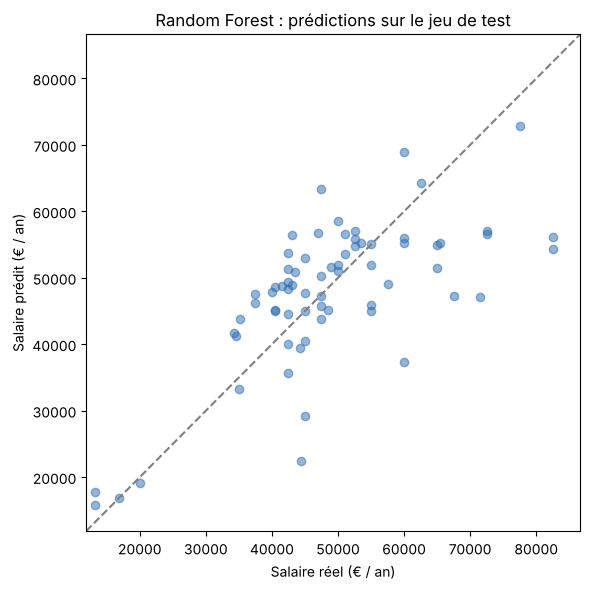

In [ ]:
meilleur_nom = df_resultats.drop("Référence (médiane)")["RMSE"].idxmin()
pred_best = pipelines[meilleur_nom].transform(test).select("salaire_annuel", "prediction").toPandas()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(pred_best.salaire_annuel, pred_best.prediction, alpha=0.5, color="#2b6cb0")
lim = [pred_best.min().min() * 0.9, pred_best.max().max() * 1.05]
ax.plot(lim, lim, "--", color="grey")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Salaire réel (€ / an)"); ax.set_ylabel("Salaire prédit (€ / an)")
ax.set_title(f"{meilleur_nom} : prédictions sur le jeu de test")
plt.tight_layout()
plt.show()

### 5.1 Interprétabilité : variables les plus prédictives

- Pour les **modèles d'arbres**, `featureImportances` mesure la réduction moyenne de variance apportée par chaque variable dans les divisions des arbres. Les importances des modalités d'une même variable catégorielle (issues du one-hot encoding) sont additionnées pour lire l'effet de la variable entière.
- Pour la **régression linéaire**, les coefficients donnent l'effet de chaque modalité ou compétence en € par an, toutes choses égales par ailleurs.

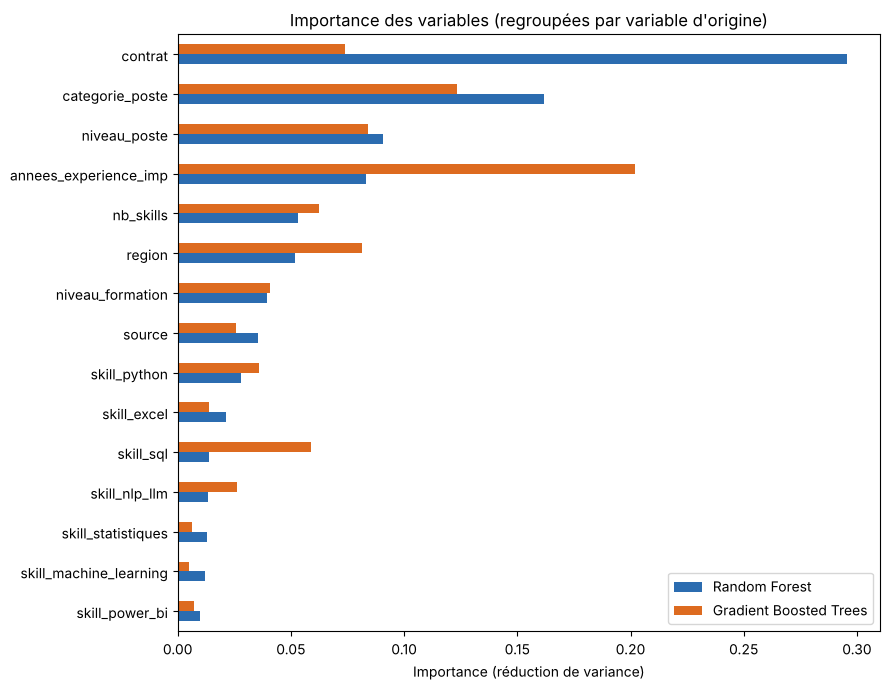

,Random Forest,Gradient Boosted Trees
contrat,0.295,0.074
categorie_poste,0.162,0.123
niveau_poste,0.091,0.084
annees_experience_imp,0.083,0.202
nb_skills,0.053,0.063
region,0.052,0.081
niveau_formation,0.039,0.041
source,0.035,0.026
skill_python,0.028,0.036
skill_excel,0.021,0.014


In [ ]:
def noms_features(modele_pipeline):
    df_tmp = modele_pipeline.transform(test.limit(1))
    attrs = df_tmp.schema["features"].metadata["ml_attr"]["attrs"]
    noms = {}
    for groupe in attrs.values():
        for a in groupe:
            noms[a["idx"]] = a["name"]
    return [noms[i] for i in range(len(noms))]

def variable_parente(nom):
    for c in CAT_COLS:
        if nom.startswith(c + "_ohe"):
            return c
    return nom

importances = {}
for nom in ["Random Forest", "Gradient Boosted Trees"]:
    m = pipelines[nom]
    imp = pd.Series(m.stages[-1].featureImportances.toArray(), index=noms_features(m))
    importances[nom] = imp.groupby(variable_parente).sum()
imp_df = pd.DataFrame(importances).sort_values("Random Forest", ascending=False)

fig, ax = plt.subplots(figsize=(9, 7))
imp_df.head(15)[::-1].plot.barh(ax=ax, color=["#2b6cb0", "#dd6b20"])
ax.set_title("Importance des variables (regroupées par variable d'origine)")
ax.set_xlabel("Importance (réduction de variance)")
plt.tight_layout()
plt.show()
imp_df.head(15).round(3)

In [ ]:
m_lr = pipelines["Régression linéaire"]
coefs = pd.Series(m_lr.stages[-1].coefficients.toArray(), index=noms_features(m_lr))
coefs = coefs[coefs != 0]
print(f"Intercept : {m_lr.stages[-1].intercept:,.0f} €")
extremes = pd.concat([coefs.sort_values(ascending=False).head(10), coefs.sort_values().head(10)[::-1]])
extremes.rename("effet sur le salaire (€/an)").round(0).to_frame()

Intercept : 41,407 €


,effet sur le salaire (€/an)
contrat_ohe_CDI,10181.0
niveau_poste_ohe_Lead / Manager,9473.0
categorie_poste_ohe_ML / IA,6009.0
skill_sas,5390.0
skill_python,5236.0
skill_dbt,5150.0
skill_nlp_llm,5144.0
contrat_ohe_Autre,4921.0
skill_databricks,3522.0
skill_spark,3118.0


### 5.2 Conclusion

**Performances.** Les trois modèles font nettement mieux que la référence naïve (prédire la médiane) : l'erreur moyenne passe d'environ 10 000 € à 7 500 € par an. Le **Random Forest** obtient la meilleure RMSE, sur le jeu de test comme en validation croisée : il capte des effets non linéaires (un stage tire le salaire vers le bas quelle que soit la compétence) que la régression linéaire ne peut pas représenter. Le GBT, l'équivalent de XGBoost, ne fait pas mieux ici : avec ~300 offres d'apprentissage, le boosting sur-apprend vite, et la validation croisée a d'ailleurs retenu sa configuration la plus prudente (arbres de profondeur 3, pas de 0,05).

**Variables les plus prédictives.** Les deux modèles d'arbres et la régression linéaire s'accordent :
1. le **type de contrat** : un stage ou une alternance divise le salaire par 2 à 3, un CDI est mieux payé qu'un CDD ou une mission d'intérim ;
2. la **catégorie de poste** : les profils ML / IA et Data Engineer sont les mieux rémunérés, les Data Analysts et BI en dessous ;
3. la **séniorité et l'expérience** (intitulé « Senior », « Lead », années d'expérience demandées) ;
4. dans une moindre mesure la **région** et le **niveau de diplôme**.

Prises une à une, les compétences pèsent moins : elles sont surtout le reflet du métier. Les outils du cloud et de la « modern data stack » (dbt, Databricks, Azure, GCP, Spark) et l'IA générative (NLP / LLM) sont associés à des salaires plus élevés, tandis qu'Excel est associé à des postes moins rémunérés.

**Limites.**
- Seules ~20 % des offres affichent un salaire : l'échantillon d'apprentissage est petit et biaisé (les entreprises qui affichent un salaire ne sont pas représentatives), ce qui explique un R² autour de 0,5 et des métriques qui varient d'un découpage à l'autre.
- Les coefficients de la régression linéaire doivent être lus avec prudence quand une compétence est rare (SAS, Hadoop) ou corrélée à d'autres : ils sont instables.
- Les compétences sont détectées par mots-clés : une approche TF-IDF ou des embeddings sur les descriptions permettrait d'aller plus loin.
- Le scraper WTTJ ne fonctionne plus depuis le changement de structure du site ; pour une collecte régulière, il faudrait passer par l'API de recherche utilisée par le site plutôt que par le HTML.

In [ ]:
spark.stop()